# Call center Optimaizition 

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
λ = 20  # calls per hour
μ = 5   # calls served per agent per hour

In [3]:
shift_hours = 8

In [4]:
np.random.seed(1)

In [5]:
# Total number of hours in the shift
total_minutes = shift_hours * 60

# Convert rates from per hour to per minute
λ_min = λ / 60     # ~0.333 calls per minute
μ_min = μ / 60     # ~0.083 services per minute

# Generate arrival times
arrival_times = []
current_time = 0

while current_time < total_minutes:
    # Generate next interarrival time
    interarrival = np.random.exponential(1 / λ_min)
    current_time += interarrival
    if current_time < total_minutes:
        arrival_times.append(current_time)

# Generate service times for each customer
service_times = np.random.exponential(1 / μ_min, size=len(arrival_times))

In [6]:
# 2. Single‐Run Simulation Function

def simulate_queue(s):
    """
    Simulate an M/M/s queue over 'shift_hours'.
    Returns arrays of wait times (hrs) and system sizes at arrivals.
    """
    # generate arrival times until end of shift
    inter = np.random.exponential(1/λ, int(λ*shift_hours*1.5))
    arrivals = np.cumsum(inter)
    arrivals = arrivals[arrivals < shift_hours]
    N = len(arrivals)

    # generate service times for each caller
    services = np.random.exponential(1/μ, N)

    # track each server’s next‐free time
    next_free = np.zeros(s)
    wait_times = np.zeros(N)
    system_size = np.zeros(N)

    # departure times list
    dep_times = []

    for i, t in enumerate(arrivals):
        # find soonest‐available agent
        j = np.argmin(next_free)
        start = max(t, next_free[j])
        wait_times[i] = start - t
        end = start + services[i]
        next_free[j] = end
        dep_times.append(end)

        # count how many callers are still in system at time t
        system_size[i] = np.sum(np.array(dep_times) > t)

    return wait_times, system_size

# quick test for s=1
w1, q1 = simulate_queue(s=1)
print(f"s=1: avg wait {w1.mean()*60:.1f} min, avg queue len {q1.mean():.2f}")

s=1: avg wait 585.1 min, avg queue len 55.87


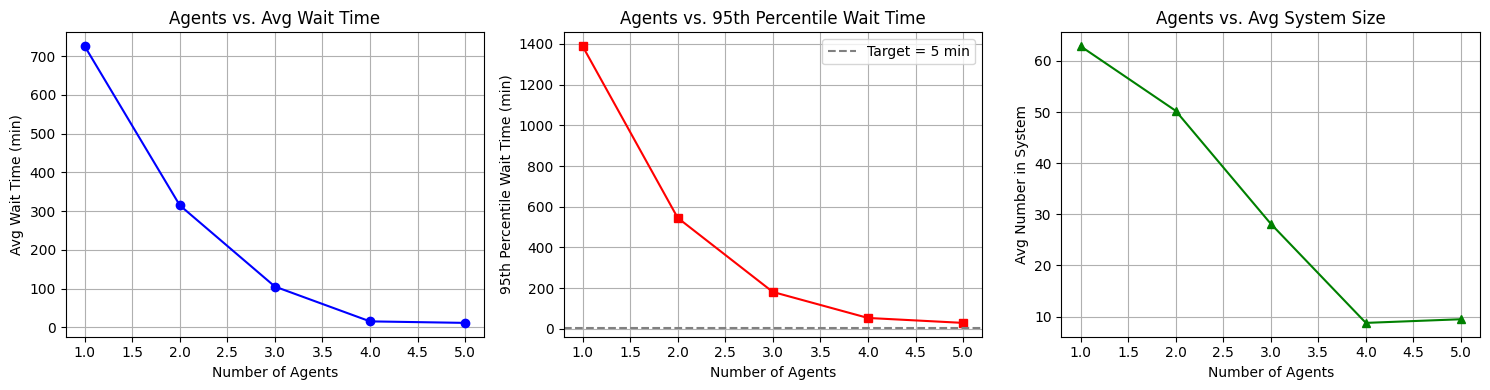

In [7]:
import matplotlib.pyplot as plt

# Run simulation for s = 1 to 5
agent_range = range(1, 6)
avg_waits = []
percentile_95_waits = []
avg_system_sizes = []

for s in agent_range:
    wait_times, system_sizes = simulate_queue(s)
    avg_waits.append(np.mean(wait_times) * 60)  # in minutes
    percentile_95_waits.append(np.percentile(wait_times, 95) * 60)  # in minutes
    avg_system_sizes.append(np.mean(system_sizes))

# Plotting
plt.figure(figsize=(15, 4))

# 1. Avg Wait Time
plt.subplot(1, 3, 1)
plt.plot(agent_range, avg_waits, marker='o', color='blue')
plt.title('Agents vs. Avg Wait Time')
plt.xlabel('Number of Agents')
plt.ylabel('Avg Wait Time (min)')
plt.grid(True)

# 2. 95th Percentile Wait Time
plt.subplot(1, 3, 2)
plt.plot(agent_range, percentile_95_waits, marker='s', color='red')
plt.title('Agents vs. 95th Percentile Wait Time')
plt.xlabel('Number of Agents')
plt.ylabel('95th Percentile Wait Time (min)')
plt.axhline(y=5, color='gray', linestyle='--', label='Target = 5 min')
plt.legend()
plt.grid(True)

# 3. Avg System Size
plt.subplot(1, 3, 3)
plt.plot(agent_range, avg_system_sizes, marker='^', color='green')
plt.title('Agents vs. Avg System Size')
plt.xlabel('Number of Agents')
plt.ylabel('Avg Number in System')
plt.grid(True)

plt.tight_layout()
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
λ = 20  # arrivals per hour
μ = 5   # service rate per agent
shift_hours = 8
max_wait_threshold = 5 / 60  # 5 minutes in hours
np.random.seed(1)

# Enhanced simulation function with abandonment
def simulate_queue_with_abandonment(s):
    inter = np.random.exponential(1 / λ, int(λ * shift_hours * 1.5))
    arrivals = np.cumsum(inter)
    arrivals = arrivals[arrivals < shift_hours]
    N = len(arrivals)

    services = np.random.exponential(1 / μ, N)
    next_free = np.zeros(s)
    wait_times = np.zeros(N)
    system_size = np.zeros(N)
    abandoned = np.zeros(N)

    dep_times = []

    for i, t in enumerate(arrivals):
        j = np.argmin(next_free)
        start = max(t, next_free[j])
        wait = start - t

        if wait > max_wait_threshold:
            abandoned[i] = 1
            continue

        wait_times[i] = wait
        end = start + services[i]
        next_free[j] = end
        dep_times.append(end)
        system_size[i] = np.sum(np.array(dep_times) > t)

    # Only include customers who did NOT abandon
    served = wait_times > 0
    mean_wait = np.mean(wait_times[served]) * 60 if np.any(served) else 0
    p95_wait = np.percentile(wait_times[served], 95) * 60 if np.any(served) else 0
    abandonment_rate = np.sum(abandoned) / N * 100
    avg_queue = np.mean(system_size)

    return mean_wait, p95_wait, abandonment_rate, avg_queue

# Simulate for s = 1 to 5
agent_range = range(1, 6)
mean_waits = []
p95_waits = []
abandon_rates = []
avg_queues = []

for s in agent_range:
    m, p, a, q = simulate_queue_with_abandonment(s)
    mean_waits.append(m)
    p95_waits.append(p)
    abandon_rates.append(a)
    avg_queues.append(q)

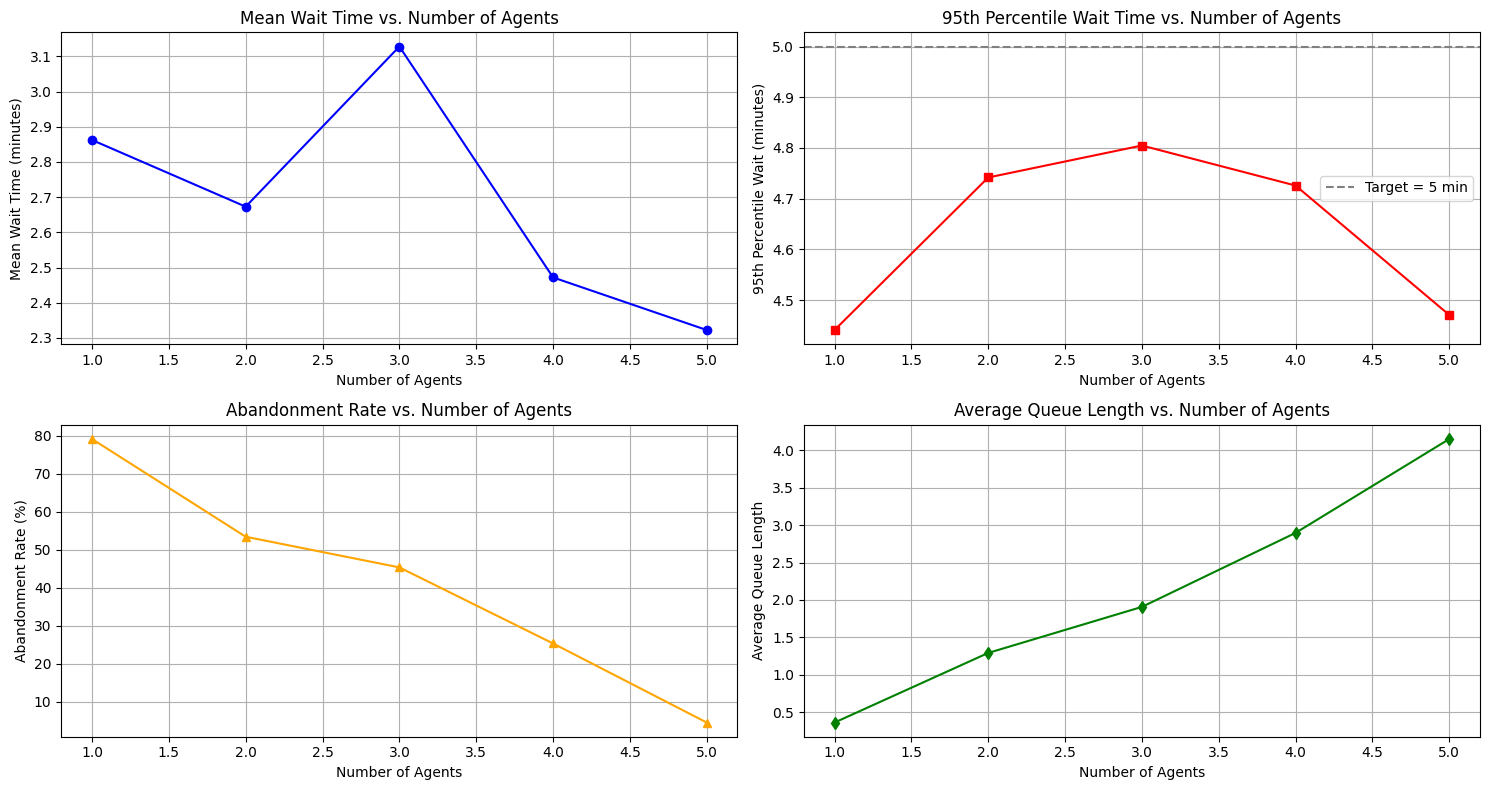

In [9]:
plt.figure(figsize=(15, 8))

# Mean Wait Time
plt.subplot(2, 2, 1)
plt.plot(agent_range, mean_waits, marker='o', color='blue')
plt.title("Mean Wait Time vs. Number of Agents")
plt.xlabel("Number of Agents")
plt.ylabel("Mean Wait Time (minutes)")
plt.grid(True)

# 95th Percentile Wait Time
plt.subplot(2, 2, 2)
plt.plot(agent_range, p95_waits, marker='s', color='red')
plt.axhline(5, color='gray', linestyle='--', label='Target = 5 min')
plt.title("95th Percentile Wait Time vs. Number of Agents")
plt.xlabel("Number of Agents")
plt.ylabel("95th Percentile Wait (minutes)")
plt.legend()
plt.grid(True)

# Abandonment Rate
plt.subplot(2, 2, 3)
plt.plot(agent_range, abandon_rates, marker='^', color='orange')
plt.title("Abandonment Rate vs. Number of Agents")
plt.xlabel("Number of Agents")
plt.ylabel("Abandonment Rate (%)")
plt.grid(True)

# Average Queue Length
plt.subplot(2, 2, 4)
plt.plot(agent_range, avg_queues, marker='d', color='green')
plt.title("Average Queue Length vs. Number of Agents")
plt.xlabel("Number of Agents")
plt.ylabel("Average Queue Length")
plt.grid(True)

plt.tight_layout()
plt.show()


In [10]:
import pandas as pd

results = pd.DataFrame({
    "Agents": list(agent_range),
    "Mean Wait (min)": mean_waits,
    "95th % Wait (min)": p95_waits,
    "Abandon Rate (%)": abandon_rates,
    "Avg Queue Length": avg_queues
})

print(results.to_string(index=False))


 Agents  Mean Wait (min)  95th % Wait (min)  Abandon Rate (%)  Avg Queue Length
      1         2.862322           4.441061         79.141104          0.361963
      2         2.672933           4.741788         53.416149          1.291925
      3         3.127862           4.804834         45.348837          1.906977
      4         2.471938           4.725886         25.324675          2.896104
      5         2.322499           4.470769          4.511278          4.150376


In [11]:
# Step 3: Compare to M/M/1 Analytic Formula


# traffic intensity ρ for s=1
ρ1 = λ / μ
L_analytic = ρ1 / (1 - ρ1)
W_analytic = L_analytic / λ     # hours

print("M/M/1 analytic vs. simulation:")
print(f"  Analytic system size L = {L_analytic:.2f}")
print(f"  Simulated avg system size = {q1.mean():.2f}")
print(f"  Analytic time in system W = {W_analytic*60:.1f} min")
print(f"  Simulated avg wait+service = {w1.mean()*60 + (1/μ)*60:.1f} min")

M/M/1 analytic vs. simulation:
  Analytic system size L = -1.33
  Simulated avg system size = 55.87
  Analytic time in system W = -4.0 min
  Simulated avg wait+service = 597.1 min


In [12]:
# Step 4: Test Staffing Levels (Agents = 1 to 5)

threshold = 5  # minutes
results = []

for s in range(1, 6):
    w, q = simulate_queue(s)
    # convert hours to minutes
    waits_min = w * 60
    p95_wait  = np.percentile(waits_min, 95)
    results.append((s, waits_min.mean(), p95_wait, q.mean()))

# tabulate
import pandas as pd
df = pd.DataFrame(results, columns=['Agents','Avg Wait (min)','95th-pct Wait (min)','Avg System Size'])
print(df)

# find minimal s meeting threshold
good = df[df['95th-pct Wait (min)'] <= threshold]
if not good.empty:
    best_s = int(good.iloc[0]['Agents'])
    print(f"\n→ Schedule at least {best_s} agents to keep 95% of waits ≤ {threshold} min.")
else:
    print("\nEven 5 agents can’t meet the 5 min 95% wait target.")

   Agents  Avg Wait (min)  95th-pct Wait (min)  Avg System Size
0       1      838.162681          1571.975924        68.708995
1       2      359.858207           658.764635        61.970149
2       3      116.513104           179.007685        34.481250
3       4        6.267267            23.905941         6.146667
4       5        5.175728            18.895394         6.828402

Even 5 agents can’t meet the 5 min 95% wait target.


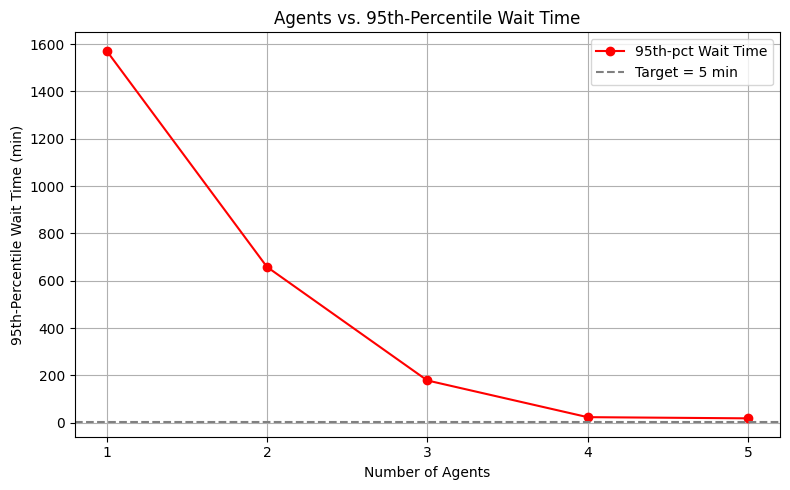

In [13]:
import matplotlib.pyplot as plt

# Plot 95th percentile wait time vs number of agents
plt.figure(figsize=(8, 5))
plt.plot(df['Agents'], df['95th-pct Wait (min)'], marker='o', linestyle='-', color='red', label='95th-pct Wait Time')

# Add target threshold line at 5 minutes
plt.axhline(y=5, color='gray', linestyle='--', linewidth=1.5, label='Target = 5 min')

# Mark the first acceptable agent count, if any
acceptable = df[df['95th-pct Wait (min)'] <= 5]
if not acceptable.empty:
    best_s = int(acceptable.iloc[0]['Agents'])
    best_wait = acceptable.iloc[0]['95th-pct Wait (min)']
    plt.scatter(best_s, best_wait, color='green', zorder=5, label=f'Min Agents = {best_s}')

# Labels and grid
plt.title("Agents vs. 95th-Percentile Wait Time")
plt.xlabel("Number of Agents")
plt.ylabel("95th-Percentile Wait Time (min)")
plt.xticks(df['Agents'])
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()


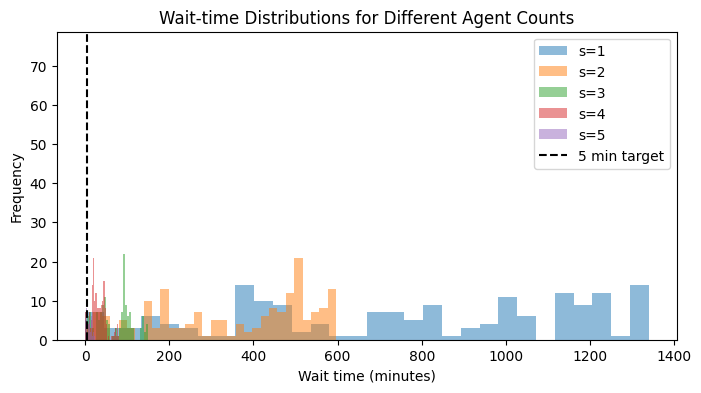

In [14]:
# Step 5: Visualize Wait‐Time Distributions

# 5. Visualize Wait‐Time Distributions


plt.figure(figsize=(8,4))
for s in [1,2,3,4,5]:
    w, _ = simulate_queue(s)
    plt.hist(w*60, bins=30, alpha=0.5, label=f's={s}')
plt.axvline(threshold, color='k', linestyle='--', label='5 min target')
plt.xlabel('Wait time (minutes)')
plt.ylabel('Frequency')
plt.title('Wait‐time Distributions for Different Agent Counts')
plt.legend()
plt.show()

In [15]:
# 6. Time-Varying Arrival Rates (Peak vs Off-Peak)

# 6. Time-Varying λ
def simulate_queue_timevarying(s):
    # define piecewise arrival rates per hour
    periods = [(0,2,30), (2,6,20), (6,8,40)]  # (start, end, λ)
    arrivals = []
    for start, end, lam in periods:
        duration = end - start
        inter = np.random.exponential(1/lam, int(lam*duration*1.5))
        ts = np.cumsum(inter) + start
        arrivals.extend(ts[ts < end])
    arrivals = np.array(arrivals)
    arrivals.sort()

    N = len(arrivals)
    services = np.random.exponential(1/μ, N)
    next_free = np.zeros(s)
    wait_times = np.zeros(N)

    for i,t in enumerate(arrivals):
        j = np.argmin(next_free)
        start = max(t, next_free[j])
        wait_times[i] = start - t
        next_free[j] = start + services[i]
    return wait_times

w_tv = simulate_queue_timevarying(s=3)
print(f"Time-varying λ, s=3 → avg wait = {w_tv.mean()*60:.1f} min")

Time-varying λ, s=3 → avg wait = 94.4 min


In [16]:
# Customer Abandonment (Patience Threshold)

# 7. Abandonment
def simulate_with_abandon(s, patience=5/60):
    arrivals = np.cumsum(np.random.exponential(1/λ, int(λ*shift_hours*1.5)))
    arrivals = arrivals[arrivals<shift_hours]
    services = np.random.exponential(1/μ, len(arrivals))
    next_free = np.zeros(s)
    waits = []
    abandons = 0

    for i,t in enumerate(arrivals):
        j = np.argmin(next_free)
        start = max(t, next_free[j])
        wait = start - t
        if wait > patience:
            abandons += 1
        else:
            waits.append(wait)
            next_free[j] = start + services[i]

    return np.array(waits), abandons/len(arrivals)

w, ab_rate = simulate_with_abandon(s=4)
print(f"Abandon rate (s=4): {ab_rate:.2%}, avg wait on served calls: {w.mean()*60:.1f} min")

# Shows the trade-off: fewer agents → more abandonments → lost revenue and satisfaction.

Abandon rate (s=4): 18.29%, avg wait on served calls: 1.1 min


In [17]:


## 8. Agent Break Scheduling

def simulate_with_breaks(s, break_start=3, break_length=0.25):
    arrivals = np.cumsum(np.random.exponential(1/λ, int(λ*shift_hours*1.5)))
    arrivals = arrivals[arrivals<shift_hours]
    services = np.random.exponential(1/μ, len(arrivals))
    next_free = np.zeros(s)
    waits = []

    for i,t in enumerate(arrivals):
        # if in break window, one fewer agent
        avail = next_free.copy()
        if break_start < t < break_start+break_length:
            avail = np.delete(avail, 0)  # remove one agent
        j = np.argmin(avail)
        start = max(t, avail[j])
        waits.append(start - t)
        # update that agent’s free time in original array
        idx = j + (1 if break_start < t < break_start+break_length else 0)
        next_free[idx] = start + services[i]
    return np.array(waits)

w_b = simulate_with_breaks(s=3)
print(f"With breaks, s=3 → avg wait = {w_b.mean()*60:.1f} min")

# See the “break-time spike” in waiting.

With breaks, s=3 → avg wait = 65.3 min


In [18]:
# 9. Cost-Based Staffing Optimization

# 9. Cost optimization
c_agent = 20   # $20/hr per agent
c_wait  = 0.50 # $0.50 per minute waited

costs = []
for s in range(1,6):
    w, _ = simulate_with_abandon(s)  # or choose another sim fn
    total_wait_cost = w.sum()*60*c_wait
    staff_cost      = s * c_agent * shift_hours
    costs.append((s, staff_cost+total_wait_cost))

opt = min(costs, key=lambda x: x[1])
print("Agent count, total cost:")
for s,c in costs: print(f" s={s}: ${c:,.0f}")
print(f" → Optimal s by cost = {opt[0]}")

Agent count, total cost:
 s=1: $213
 s=2: $392
 s=3: $546
 s=4: $699
 s=5: $849
 → Optimal s by cost = 1


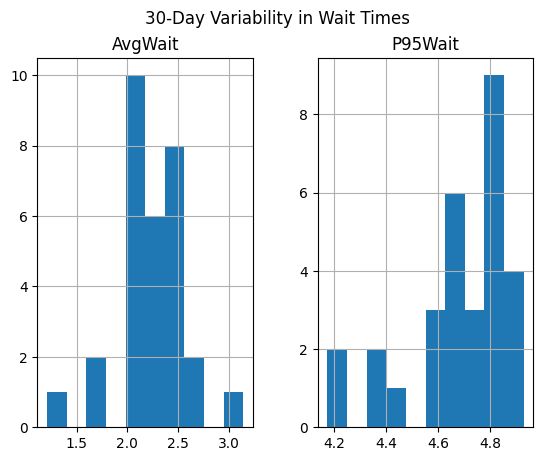

In [19]:
# 10. Multi-Day Variability & Sensitivity Analysis

# 10. 30-day simulation
days = 30
daily = []
for _ in range(days):
    w,_ = simulate_with_abandon(opt[0])
    daily.append((w.mean()*60, np.percentile(w*60,95)))
df_days = pd.DataFrame(daily, columns=['AvgWait','P95Wait'])
df_days.describe()
df_days.hist(bins=10)
plt.suptitle('30-Day Variability in Wait Times')
plt.show()